In [5]:
!pip install PyMPDATA

In [28]:
import PyMPDATA as mp
import numpy as np
import matplotlib.pyplot as plt

from PyMPDATA import ScalarField, VectorField, Options, boundary_conditions as bc, Stepper, Solver

In [48]:
options=Options(n_iters=4,infinite_gauge=True, nonoscillatory=True, third_order_terms=True)
# dictionary
common={
    'halo':options.n_halo,
    'boundary_conditions':(bc.Periodic(),)
    }

psi=ScalarField(**common, data=(np.exp(-(x:=np.linspace(-2,8,40))**2)))
C=VectorField(**common, data=(np.full(x.size+1,1/4),))

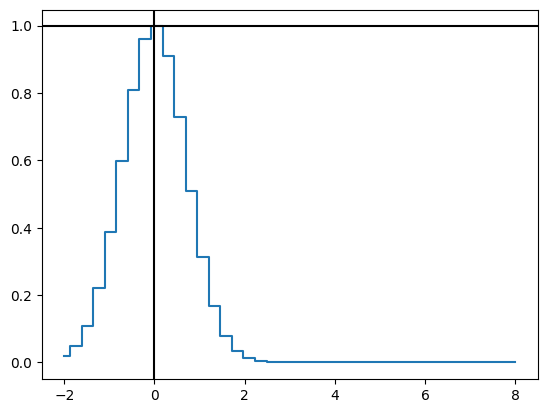

In [49]:
plt.step(x,psi.get(),where='mid')
plt.axvline(0,color='k')
plt.axhline(1,color='k')

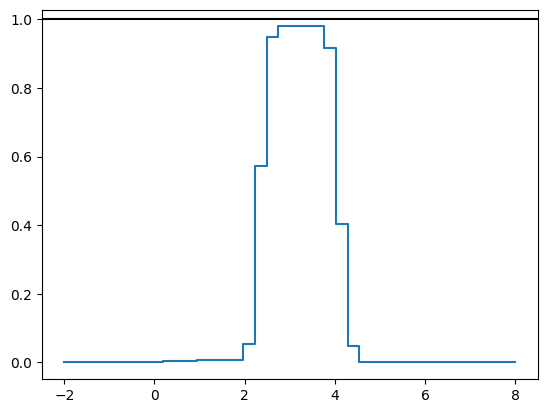

In [55]:
solver=Solver(advector=C,advectee=psi,stepper=Stepper(n_dims=1,options=options))
solver.advance(390)
plt.step(x,psi.get(),where='mid')
# plt.axvline(0,color='k')
plt.axhline(1,color='k')